# Module 3 · Notebook 3: The experiment

**Question: why does training without warmup get stuck, and why does warmup fix it?**

Every GPT recipe uses learning-rate warmup. The usual explanation is a vague "big steps at the start are unstable". This notebook measures what actually goes wrong.

It started as a hunt for loss spikes. A scout before this notebook trained the model for 200 steps in 8 settings, and **none of them spiked**:

| peak lr | no warmup, no clip | no warmup, clip 1.0 | warmup 50, no clip | warmup 50, clip 1.0 |
|---|---|---|---|---|
| 3e-2 | 3.16 | 2.93 | 2.66 | 2.66 |
| 1e-2 | 2.62 | 2.59 | 2.52 | 2.50 |

(Train loss at step 200. This scout's code isn't in the repo.) Sudden spikes seem to be mostly a large-scale effect (Molybog et al. 2023 study them at 7B–546B parameters). What the scout did show: **every run without warmup first drops to ~3.1 and stays there for a while**, which is exactly the unigram loss from notebook 1. How long depends on the learning rate and on clipping: at 3e-2 without clipping it is still there at step 200; with clipping (2.93) or at 1e-2 (2.62) it gets out later. With warmup it never gets stuck there. So that became the question.

| Step | What we do | Runtime |
|---|---|---|
| 1 | The symptom: two runs at lr 3e-2, without and with warmup | ~14 min |
| 2 | Is it really "unigram"? A measure of how much the prediction depends on the context | — |
| 3 | Where does it break? How different the positions still are, block by block | — |
| 4 | Two suspects: attention collapse and the biases | ~14 min |
| 5 | The cause, with a causal test | ~5 min |
| 6 | Module 2's √d question, re-checked with Adam | ~2 min |

**Runtime:** about 35 minutes on a laptop CPU.

In [1]:
import sys, time, math, gc
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

LAB = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(LAB / "02-attention"))
from transformer import block, init_block, layer_norm, split_heads, merge_heads, attention, mlp, swap_last2
from autograd import Tensor, softmax, cross_entropy

print("python", sys.version.split()[0], "| numpy", np.__version__)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

python 3.12.15 | numpy 2.5.3


The data, the model and AdamW from notebooks 1 and 2, unchanged. Two additions:

- an option for **qk-layernorm** (Step 4): LayerNorm on the queries and keys of every head before the dot product;
- `train_step` from notebook 2, with the `gc.collect()` that frees each step's graph.

In [2]:
raw = (LAB / "03-gpt" / "data" / "sherlock_raw.txt").read_text(encoding="utf-8-sig").replace("\r\n", "\n")
start = raw.find("*** START OF THE PROJECT GUTENBERG EBOOK")
end = raw.find("*** END OF THE PROJECT GUTENBERG EBOOK")
text = raw[raw.find("\n", start) + 1:end].strip()
chars = sorted(set(text))
V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
data = np.array([stoi[c] for c in text], dtype=np.int64)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
UNIGRAM, BIGRAM = 3.103, 2.433        # val losses from notebook 1

def get_batch(data, B, T, rng):
    ix = rng.integers(0, len(data) - T, B)
    return np.stack([data[i:i + T] for i in ix]), np.stack([data[i + 1:i + T + 1] for i in ix])

def embedding(weight, idx):
    out = Tensor(weight.data[idx], (weight,), "embedding")
    def _backward():
        np.add.at(weight.grad, idx, out.grad)
    out._backward = _backward
    return out

cfg = dict(V=V, T=128, C=128, L=4, H=4)

def init_gpt(cfg, rng, qk=False):
    V, T, C, L = cfg["V"], cfg["T"], cfg["C"], cfg["L"]
    p = {"wte": rng.standard_normal((V, C)) * 0.02, "wpe": rng.standard_normal((T, C)) * 0.02,
         "lnf_g": np.ones(C), "lnf_b": np.zeros(C)}
    for i in range(L):
        for k, v in init_block(C, rng).items():
            p[f"h{i}.{k}"] = v
        if qk:
            hs = C // cfg["H"]
            p[f"h{i}.qn_g"], p[f"h{i}.qn_b"] = np.ones(hs), np.zeros(hs)
            p[f"h{i}.kn_g"], p[f"h{i}.kn_b"] = np.ones(hs), np.zeros(hs)
    return p

def block_qk(x, p, H):
    # Module 2's block, with a LayerNorm on q and k (per head) before the dot product
    h = layer_norm(x, p["ln1_g"], p["ln1_b"])
    q, k, v = split_heads(h @ p["Wq"], H), split_heads(h @ p["Wk"], H), split_heads(h @ p["Wv"], H)
    q, k = layer_norm(q, p["qn_g"], p["qn_b"]), layer_norm(k, p["kn_g"], p["kn_b"])
    x = x + merge_heads(attention(q, k, v)) @ p["Wo"]
    h = layer_norm(x, p["ln2_g"], p["ln2_b"])
    return x + mlp(h, p["W1"], p["b1"], p["W2"], p["b2"])

def gpt(P, idx, qk=False):
    B, T = idx.shape
    x = embedding(P["wte"], idx) + embedding(P["wpe"], np.arange(T))
    for i in range(cfg["L"]):
        pre = f"h{i}."
        bp = {k[len(pre):]: v for k, v in P.items() if k.startswith(pre)}
        x = block_qk(x, bp, cfg["H"]) if qk else block(x, bp, cfg["H"])
    x = layer_norm(x, P["lnf_g"], P["lnf_b"])
    return x @ P["wte"].transpose((1, 0))

class AdamW:
    def __init__(self, P, betas=(0.9, 0.99), eps=1e-8, weight_decay=0.1):
        self.P = P
        self.b1, self.b2 = betas
        self.eps, self.wd = eps, weight_decay
        self.m = {k: np.zeros_like(p.data) for k, p in P.items()}
        self.v = {k: np.zeros_like(p.data) for k, p in P.items()}
        self.t = 0

    def step(self, lr):
        self.t += 1
        for k, p in self.P.items():
            g = p.grad
            self.m[k] = self.b1 * self.m[k] + (1 - self.b1) * g
            self.v[k] = self.b2 * self.v[k] + (1 - self.b2) * g * g
            m_hat = self.m[k] / (1 - self.b1**self.t)
            v_hat = self.v[k] / (1 - self.b2**self.t)
            if p.data.ndim >= 2:
                p.data -= lr * self.wd * p.data
            p.data -= lr * m_hat / (np.sqrt(v_hat) + self.eps)

def train_step(P, opt, rng, lr, qk=False, B=32):
    for p in P.values():
        p.grad = np.zeros_like(p.data)
    x, y = get_batch(train_data, B, cfg["T"], rng)
    loss = cross_entropy(gpt(P, x, qk).reshape(-1, V), y.reshape(-1))
    loss.backward()
    opt.step(lr)
    return float(loss.data)

print(f"vocab {V}, {sum(v.size for v in init_gpt(cfg, np.random.default_rng(0)).values()):,} parameters")

vocab 88, 818,944 parameters


### The measuring tool

To see *inside* the model while it trains, `measure()` re-runs the forward pass in plain NumPy (no graph, so it is cheap) on 4 fixed val sequences and keeps:

| measure | what it says |
|---|---|
| **largest attention score** per layer | the biggest $q\cdot k/\sqrt{d}$. Large = softmax saturated |
| **attention entropy** per layer | 1 = attention spread evenly over the visible tokens, 0 = all on one token |
| **position variation**, input and after each block | how much the vectors at different positions differ, relative to the part all positions share. ~0 = every position looks the same |
| **context measure** | how much the predicted distribution changes from position to position (mean KL divergence from the average prediction). **0 = the same prediction everywhere, which is all a unigram model can do** |

A measuring tool is only useful if it measures the real model, so first: does its forward pass give the same logits as the engine?

In [3]:
def _ln(x, g, b, eps=1e-5):
    xc = x - x.mean(-1, keepdims=True)
    return xc * ((xc**2).mean(-1, keepdims=True) + eps)**-0.5 * g + b

def _softmax(z):
    e = np.exp(z - z.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

def _gelu(x):
    return 0.5 * x * (1 + np.tanh(math.sqrt(2 / math.pi) * (x + 0.044715 * x**3)))

def pos_variation(x):
    # (B, T, C): size of what differs between positions / size of what all positions share
    shared = x.mean(1, keepdims=True)
    return float(np.linalg.norm(x - shared) / np.linalg.norm(np.broadcast_to(shared, x.shape)))

def measure(p, idx, qk=False):
    B, T = idx.shape
    C, H = cfg["C"], cfg["H"]
    hs = C // H
    split = lambda a: a.reshape(B, T, H, hs).transpose(0, 2, 1, 3)
    mask = np.triu(np.full((T, T), -np.inf), k=1)
    m = {"att_max": [], "att_ent": [], "pos_var": []}
    x = p["wte"][idx] + p["wpe"][:T]
    m["pos_var"].append(pos_variation(x))
    for i in range(cfg["L"]):
        g = lambda k: p[f"h{i}.{k}"]
        h = _ln(x, g("ln1_g"), g("ln1_b"))
        q, k, v = split(h @ g("Wq")), split(h @ g("Wk")), split(h @ g("Wv"))
        if qk:
            q, k = _ln(q, g("qn_g"), g("qn_b")), _ln(k, g("kn_g"), g("kn_b"))
        s = q @ k.transpose(0, 1, 3, 2) / math.sqrt(hs)
        m["att_max"].append(float(np.abs(np.tril(s)).max()))
        a = _softmax(s + mask)
        plogp = np.where(a > 0, a * np.log(np.where(a > 0, a, 1.0)), 0.0).sum(-1)
        m["att_ent"].append(float((-plogp[..., 1:] / np.log(np.arange(2, T + 1))).mean()))
        x = x + (a @ v).transpose(0, 2, 1, 3).reshape(B, T, C) @ g("Wo")
        h = _ln(x, g("ln2_g"), g("ln2_b"))
        x = x + _gelu(h @ g("W1") + g("b1")) @ g("W2") + g("b2")
        m["pos_var"].append(pos_variation(x))
    logits = _ln(x, p["lnf_g"], p["lnf_b"]) @ p["wte"].T
    probs = _softmax(logits)
    avg = probs.reshape(-1, V).mean(0)
    m["context"] = float((probs * (np.log(probs + 1e-30) - np.log(avg + 1e-30))).sum(-1).mean())
    return m, logits

XD, _ = get_batch(val_data, 4, cfg["T"], np.random.default_rng(7))     # the 4 fixed sequences

for qk in (False, True):
    p = init_gpt(cfg, np.random.default_rng(0), qk=qk)
    engine = gpt({k: Tensor(v) for k, v in p.items()}, XD, qk).data
    print(f"qk-layernorm {qk!s:5}: max |measure() - engine| on the logits = {np.abs(measure(p, XD, qk)[1] - engine).max():.1e}")
gc.collect()

qk-layernorm False: max |measure() - engine| on the logits = 1.0e-15
qk-layernorm True : max |measure() - engine| on the logits = 9.4e-16


3031

Equal to ~1e-15, so everything below describes the real model.

One more reference number: the context measure of the **bigram** model from notebook 1 on the same 4 sequences. A model that uses the previous character should be around there; one that ignores the context is at 0.

In [4]:
counts2 = np.ones((V, V))
np.add.at(counts2, (train_data[:-1], train_data[1:]), 1)
p2 = (counts2 / counts2.sum(1, keepdims=True))[XD]          # bigram prediction at every position
avg2 = p2.reshape(-1, V).mean(0)
BIGRAM_CONTEXT = float((p2 * (np.log(p2) - np.log(avg2))).sum(-1).mean())
print(f"context measure: unigram 0 (by definition), bigram {BIGRAM_CONTEXT:.2f}")

context measure: unigram 0 (by definition), bigram 0.64


## Step 1: The symptom

The same model, data and seed, AdamW at a peak learning rate of 3e-2 (10× the one notebook 2 trained with, to make the problem obvious), no clipping, 200 steps. The only difference: 50 steps of warmup or none. The measures are taken every step for the first 30 steps, then every 10.

`run()` also has the options used later: freezing the biases, qk-layernorm, and editing the update (Step 5).

In [5]:
BIASES = ("ln1_b", "ln2_b", "b1", "b2", "lnf_b")

def top_direction(M):
    U, s, Vt = np.linalg.svd(M, full_matrices=False)
    return s[0] * np.outer(U[:, 0], Vt[0])

def edit_update(P, before, how):
    # change what the optimizer just did to every weight matrix (Step 5)
    for k, p in P.items():
        if p.data.ndim != 2:
            continue
        dW = p.data - before[k]
        new = dW - top_direction(dW)                     # remove the strongest direction
        if how == "shrink":                              # or: same size as that, but every direction kept
            new = dW * np.linalg.norm(new) / np.linalg.norm(dW)
        p.data = before[k] + new

def run(lr, warmup=0, steps=200, freeze_biases=False, qk=False, edit=None):
    P = {k: Tensor(v) for k, v in init_gpt(cfg, np.random.default_rng(0), qk=qk).items()}
    trained = {k: p for k, p in P.items() if not (freeze_biases and k.split(".")[-1] in BIASES)}
    opt = AdamW(trained)
    rng = np.random.default_rng(1)
    log = {"loss": [], "step": [], "m": []}
    for step in range(steps + 1):
        if step <= 30 or step % 10 == 0:
            log["step"].append(step)
            log["m"].append(measure({k: p.data for k, p in P.items()}, XD, qk)[0])
        if step == steps:
            break
        before = {k: p.data.copy() for k, p in P.items()} if edit else None
        log["loss"].append(train_step(P, opt, rng, lr * min(1, (step + 1) / warmup) if warmup else lr, qk))
        if edit:
            edit_update(P, before, edit)
        gc.collect()
    return log

def series(log, key, layer=None):
    return np.array([m[key] if layer is None else m[key][layer] for m in log["m"]])

runs = {}
for name, kw in [("no warmup", {}), ("warmup", {"warmup": 50})]:
    t0 = time.perf_counter()
    runs[name] = run(3e-2, **kw)
    print(f"{name:10s} loss at step 200 {runs[name]['loss'][-1]:.3f}  [{time.perf_counter() - t0:.0f}s]", flush=True)

no warmup  loss at step 200 3.154  [406s]
warmup     loss at step 200 2.666  [409s]


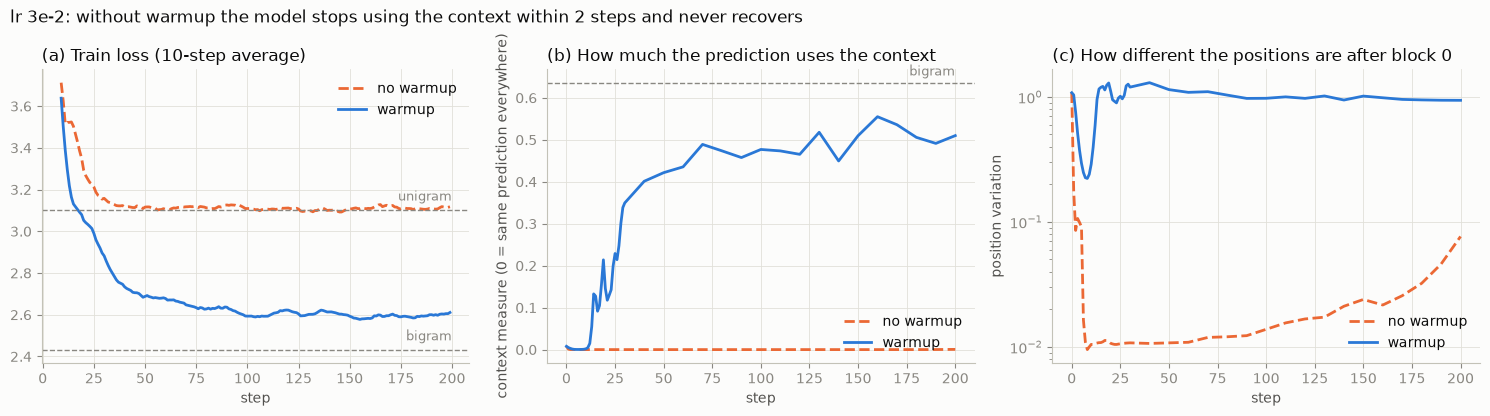

In [6]:
STYLE = {"no warmup": (SERIES[1], "--"), "warmup": (SERIES[0], "-"),
         "biases frozen": (SERIES[2], "-."), "qk-layernorm": (SERIES[3], ":")}

def smooth(y, k=10):
    return np.convolve(y, np.ones(k) / k, mode="valid")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for name in ("no warmup", "warmup"):
    c, ls = STYLE[name]
    log = runs[name]
    axes[0].plot(np.arange(9, len(log["loss"])), smooth(log["loss"]), color=c, ls=ls, label=name)
    axes[1].plot(log["step"], series(log, "context"), color=c, ls=ls, label=name)
    axes[2].plot(log["step"], series(log, "pos_var", 1), color=c, ls=ls, label=name)
for y, lab in [(UNIGRAM, "unigram"), (BIGRAM, "bigram")]:
    axes[0].axhline(y, color=MUTED, ls="--", lw=1)
    axes[0].text(200, y + 0.03, lab, color=MUTED, fontsize=9, ha="right", va="bottom")
axes[1].axhline(BIGRAM_CONTEXT, color=MUTED, ls="--", lw=1)
axes[1].text(200, BIGRAM_CONTEXT + 0.01, "bigram", color=MUTED, fontsize=9, ha="right", va="bottom")
axes[0].set_title("(a) Train loss (10-step average)", loc="left")
axes[1].set_title("(b) How much the prediction uses the context", loc="left")
axes[2].set_title("(c) How different the positions are after block 0", loc="left")
axes[1].set_ylabel("context measure (0 = same prediction everywhere)")
axes[2].set_ylabel("position variation")
axes[2].set_yscale("log")
for ax in axes:
    ax.set_xlabel("step")
    ax.legend(loc="upper right" if ax is axes[0] else "lower right")
fig.suptitle("lr 3e-2: without warmup the model stops using the context within 2 steps and never recovers",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**(a)** With warmup the loss falls past the unigram and bigram lines. Without warmup it drops to ~3.1 in a few steps and stays there for all 200.

## Step 2: Is it really "unigram"?

A loss of 3.1 could be a coincidence. **(b)** says it is not: without warmup the context measure stays at **~0.000 from step 2 on**. The model gives the *same* prediction at every position, whatever the text says. That is exactly a unigram model: the best you can do without context is to predict the overall character frequencies, and that loss is 3.10. With warmup the context measure climbs towards the bigram's.

(The warmup run also dips in (c), to ~0.2 around step 8, and is back by step 15. Every run first learns the character frequencies, and that phase pushes all positions towards the same prediction. The difference is that the warmup run gets out of it.)

## Step 3: Where does it break?

**(c)** shows the position variation after block 0. Block by block, without warmup:

In [7]:
log = runs["no warmup"]
print("position variation:   input   after block 0     1      2      3")
for s in (0, 1, 2, 5, 10, 50, 200):
    i = log["step"].index(s)
    print(f"  step {s:3d}           " + "   ".join(f"{v:5.2f}" for v in log["m"][i]["pos_var"]))

position variation:   input   after block 0     1      2      3
  step   0            4.67    1.08    0.72    0.61    0.54
  step   1            1.06    0.18    0.18    0.20    0.17
  step   2            0.82    0.09    0.04    0.02    0.02
  step   5            0.68    0.09    0.15    0.09    0.05
  step  10            0.66    0.01    0.01    0.00    0.00
  step  50            0.67    0.01    0.01    0.00    0.00
  step 200            0.78    0.08    0.04    0.03    0.02


The input still differs from position to position (~0.7: the characters are still distinguishable), but **after block 0 almost nothing is left** (~0.01). So block 0 adds something to every position that is large and *the same everywhere*, and it drowns out the tokens. The later blocks then have nothing to work with. (By step 200 it has crept up to ~0.08, but the loss and the context measure haven't moved.)

What is block 0 adding, and why? Two suspects first.

## Step 4: Two suspects

**Suspect 1: attention collapse.** Wortsman et al. (2023, "Small-scale proxies for large-scale Transformer training instabilities") show that at high learning rates the attention scores grow until softmax is one-hot ("attention entropy collapse"), the same saturation as Module 2's √d experiment, but during training.

**Suspect 2: the biases.** They start at 0, they are added to every position equally, and Adam moves every entry by about ±lr per step. At lr 3e-2 that is more than the embeddings themselves (std 0.02).

Two more runs, both without warmup: one with all biases frozen at 0 (many recent LLMs have none), one with qk-layernorm, the fix from the Wortsman paper (it caps the attention scores).

In [8]:
for name, kw in [("biases frozen", {"freeze_biases": True}), ("qk-layernorm", {"qk": True})]:
    t0 = time.perf_counter()
    runs[name] = run(3e-2, **kw)
    print(f"{name:14s} loss at step 200 {runs[name]['loss'][-1]:.3f}  [{time.perf_counter() - t0:.0f}s]", flush=True)

print("\n                 layer-0 largest score (step 30 / 200)   layer-0 entropy (200)   context (2 / 200)   pos. var. after block 0 (2)")
for name in ("no warmup", "warmup", "biases frozen", "qk-layernorm"):
    log = runs[name]
    at = lambda s, key, layer=None: series(log, key, layer)[log["step"].index(s)]
    print(f"  {name:14s} {at(30, 'att_max', 0):10.0f} / {at(200, 'att_max', 0):6.0f}"
          f"                {at(200, 'att_ent', 0):.2f}               {at(2, 'context'):.3f} / {at(200, 'context'):.3f}"
          f"          {at(2, 'pos_var', 1):.2f}")

biases frozen  loss at step 200 2.883  [407s]
qk-layernorm   loss at step 200 2.683  [448s]

                 layer-0 largest score (step 30 / 200)   layer-0 entropy (200)   context (2 / 200)   pos. var. after block 0 (2)
  no warmup             461 /    389                0.02               0.000 / 0.001          0.09
  warmup                107 /   2643                0.01               0.003 / 0.510          0.75
  biases frozen         362 /   4308                0.00               0.000 / 0.227          0.09
  qk-layernorm            7 /     17                0.66               0.000 / 0.398          0.09


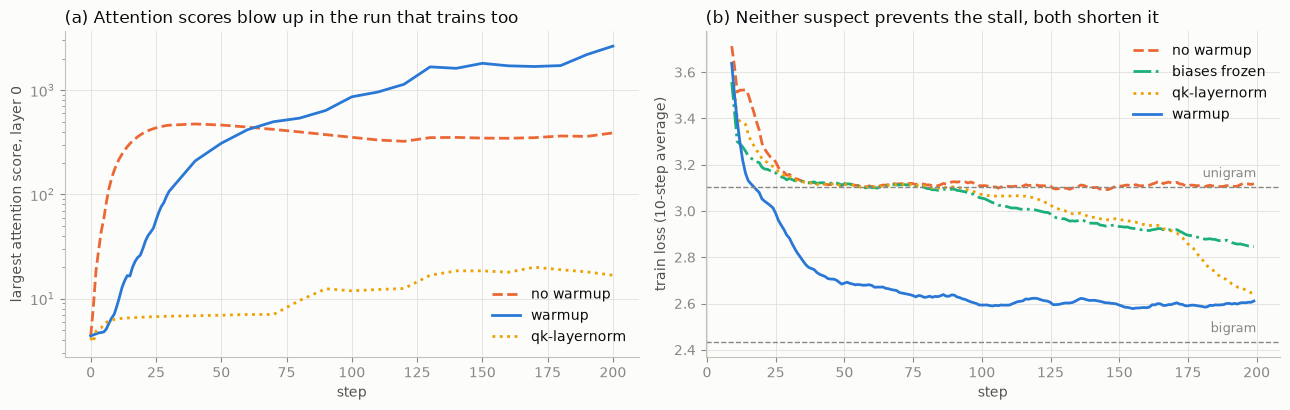

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for name in ("no warmup", "warmup", "qk-layernorm"):
    c, ls = STYLE[name]
    ax1.plot(runs[name]["step"], series(runs[name], "att_max", 0), color=c, ls=ls, label=name)
for name in ("no warmup", "biases frozen", "qk-layernorm", "warmup"):
    c, ls = STYLE[name]
    ax2.plot(np.arange(9, 200), smooth(runs[name]["loss"]), color=c, ls=ls, label=name)
ax1.set_yscale("log")
ax1.set_xlabel("step")
ax1.set_ylabel("largest attention score, layer 0")
ax1.set_title("(a) Attention scores blow up in the run that trains too", loc="left")
ax1.legend(loc="lower right")
for y, lab in [(UNIGRAM, "unigram"), (BIGRAM, "bigram")]:
    ax2.axhline(y, color=MUTED, ls="--", lw=1)
    ax2.text(200, y + 0.03, lab, color=MUTED, fontsize=9, ha="right", va="bottom")
ax2.set_xlabel("step")
ax2.set_ylabel("train loss (10-step average)")
ax2.set_title("(b) Neither suspect prevents the stall, both shorten it", loc="left")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

Neither suspect is the cause of the collapse:

- **Attention:** the stuck run has gone context-blind at step 2, when its largest attention score is still ~18 (chart (a)), so the attention scores can't be what starts it. Later, the run **with** warmup, the one that trains, ends up with the *larger* scores (thousands by step 200, against a few hundred) and layer-0 entropy just as close to 0: one-hot attention in layer 0 does not stop a model from learning. (At step 30 it is the other way round, 461 against 107 in the table.)
- **Both interventions collapse at step 2 exactly like the baseline** (same context measure, same position variation after block 0).

But both **escape** later, around step 90 (biases frozen) and 120 (qk-layernorm), and the baseline doesn't within 200 steps. So there are two different things here: what *causes* the collapse (something in the first steps that neither the biases nor the attention scores explain), and what *keeps it stuck* (the biases and unbounded attention scores both help to keep it there).

## Step 5: The cause

What else is in the first step? Notebook 2 proved that Adam's first update is $\pm\text{lr}$ for every parameter, whatever its gradient: it is the **sign** of the gradient. Two questions about that update, for each weight matrix:

1. **Is it one shared direction?** The share of the update's energy in its single strongest direction (from the SVD: $s_1^2 / \sum s_i^2$). For comparison, the same number for a random matrix of ±1.
2. **How big is that direction compared with the matrix?** Its strength $s_1$ divided by the strongest direction already in the matrix at init.

In [10]:
P = {k: Tensor(v) for k, v in init_gpt(cfg, np.random.default_rng(0)).items()}
before = {k: p.data.copy() for k, p in P.items()}
opt = AdamW(P)
train_step(P, opt, np.random.default_rng(1), 3e-2)       # exactly step 1 of the no-warmup run
grads = {k: p.grad.copy() for k, p in P.items()}

def share(M):
    s = np.linalg.svd(M, compute_uv=False)
    return s[0]**2 / (s**2).sum(), s[0]

rng = np.random.default_rng(9)
print("               energy in the top direction                strength of that direction vs the matrix")
print(f"{'matrix':9s} {'gradient':>9s} {'update':>8s} {'random ±1':>10s}       {'lr 3e-2':>8s} {'with warmup (step 1 = lr/50)':>30s}")
for k in ["h0.Wq", "h0.Wk", "h0.Wv", "h0.Wo", "h0.W1", "h0.W2", "h3.W2", "wte"]:
    dW = P[k].data - before[k]
    g_share, _ = share(grads[k])
    u_share, u_s1 = share(dW)
    r_share, _ = share(np.sign(rng.standard_normal(dW.shape)))
    ratio = u_s1 / np.linalg.svd(before[k], compute_uv=False)[0]
    print(f"{k:9s} {g_share:9.0%} {u_share:8.0%} {r_share:10.0%}       {ratio:7.1f}x {ratio / 50:24.2f}x")
del P, opt
gc.collect()

               energy in the top direction                strength of that direction vs the matrix
matrix     gradient   update  random ±1        lr 3e-2   with warmup (step 1 = lr/50)
h0.Wq           40%      21%         3%           0.9x                     0.02x
h0.Wk           24%      12%         3%           0.7x                     0.01x
h0.Wv           87%      49%         3%           1.3x                     0.03x
h0.Wo           82%      48%         3%           1.3x                     0.03x
h0.W1           82%      45%         2%           1.8x                     0.04x
h0.W2           92%      58%         2%           4.0x                     0.08x
h3.W2           99%      76%         2%           4.5x                     0.09x
wte             94%      75%         4%           6.7x                     0.13x


2302

1. **The gradients at init point mostly one way**: 80–99% of their energy in one direction for the value, output, MLP and embedding matrices (the query and key matrices less, 24–40%). That makes sense: at init the model knows nothing, so the gradient at *every* position says the same thing, "predict the common characters more".
2. **Adam's sign-like update keeps about half of that** (45–76%, against 2–4% for a random ±1 matrix).
3. **And it is huge**: at lr 3e-2 that one direction is **0.7–4.5× as strong as the strongest direction already in the matrix** (4.0× in block 0's W2, 4.5× in block 3's), and 6.7× in the token embedding. Block 0's output is now dominated by one vector that is the same for every position, which is the collapse in Step 3. With warmup, the same direction is 0.02–0.13× the matrix: too small to take over.

That is still a correlation. The **causal test**: run the no-warmup training again, and after every optimizer step, edit the update of every weight matrix:

- **top removed**: subtract only its strongest direction;
- **shrunk evenly** (the control): scale the whole update down so it is *as small as* the "top removed" one, keeping every direction.

If the size of the update is the problem, both should help about equally. If that one direction is the problem, only "top removed" should. 30 steps each, at the full lr 3e-2, no warmup.

In [11]:
for name, kw in [("top removed", {"edit": "top"}), ("shrunk evenly", {"edit": "shrink"})]:
    t0 = time.perf_counter()
    runs[name] = run(3e-2, steps=30, **kw)
    print(f"{name:13s} [{time.perf_counter() - t0:.0f}s]", flush=True)

print("\n                   position variation after block 0      context measure          loss at step 30")
print("                    step 2   step 10   step 30           step 10   step 30")
for name in ("no warmup", "shrunk evenly", "top removed", "warmup"):
    log = runs[name]
    at = lambda s, key, layer=None: series(log, key, layer)[log["step"].index(s)]
    print(f"  {name:15s} {at(2, 'pos_var', 1):7.2f} {at(10, 'pos_var', 1):8.2f} {at(30, 'pos_var', 1):9.2f}"
          f"           {at(10, 'context'):7.3f} {at(30, 'context'):9.3f}          {np.mean(log['loss'][25:30]):.2f}")

top removed   [65s]
shrunk evenly [64s]

                   position variation after block 0      context measure          loss at step 30
                    step 2   step 10   step 30           step 10   step 30
  no warmup          0.09     0.01      0.01             0.000     0.000          3.13
  shrunk evenly      0.08     0.05      0.03             0.000     0.000          3.11
  top removed        0.51     0.62      1.13             0.046     0.429          2.71
  warmup             0.75     0.29      1.20             0.002     0.350          2.83


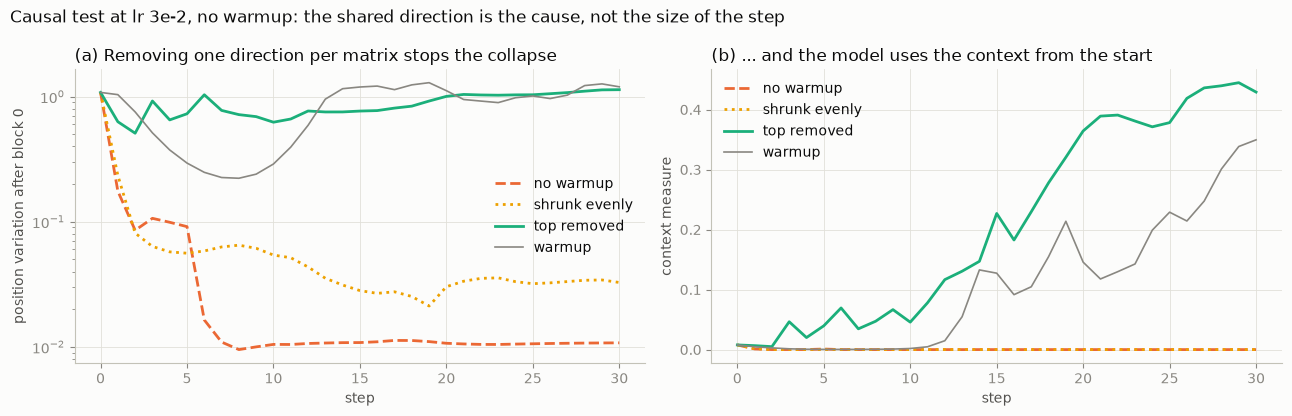

In [12]:
CAUSAL = {"no warmup": (SERIES[1], "--"), "shrunk evenly": (SERIES[3], ":"), "top removed": (SERIES[2], "-"),
          "warmup": (MUTED, "-")}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for name, (c, ls) in CAUSAL.items():
    log = runs[name]
    k = log["step"].index(30) + 1
    lw = 1.2 if name == "warmup" else 2
    ax1.plot(log["step"][:k], series(log, "pos_var", 1)[:k], color=c, ls=ls, lw=lw, label=name)
    ax2.plot(log["step"][:k], series(log, "context")[:k], color=c, ls=ls, lw=lw, label=name)
ax1.set_yscale("log")
ax1.set_ylabel("position variation after block 0")
ax1.set_title("(a) Removing one direction per matrix stops the collapse", loc="left")
ax2.set_ylabel("context measure")
ax2.set_title("(b) ... and the model uses the context from the start", loc="left")
ax1.legend(loc="center right")
ax2.legend(loc="upper left")
for ax in (ax1, ax2):
    ax.set_xlabel("step")
fig.suptitle("Causal test at lr 3e-2, no warmup: the shared direction is the cause, not the size of the step",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Shrunk evenly** is exactly as small as top removed (by construction, matrix by matrix), and collapses just like the normal run: the size of the step is not the problem. **Top removed** never collapses: the positions stay different, the model uses the context from the first steps, and at step 30 it is at least as far along as the normal run **with** warmup, at a 50× larger learning rate in the first steps.

Removing that one direction every step is a diagnostic tool here, not a training method: it was only run for 30 steps, and nothing says it is a good idea in general.

### Does it scale with the learning rate?

If this is the mechanism, the collapse should get deeper the larger the steps. No warmup, 30 steps each:

In [13]:
for lr in (3e-3, 1e-2):
    runs[f"lr {lr:g}"] = run(lr, steps=30)
runs["lr 0.03"] = runs["no warmup"]

print("no warmup        position variation after block 0 / context measure")
print("                 step 2          step 10         step 30")
for lr in (3e-3, 1e-2, 3e-2):
    log = runs[f"lr {lr:g}"]
    print(f"  lr {lr:<8g}" + "".join(f"   {series(log, 'pos_var', 1)[log['step'].index(s)]:.2f} / {series(log, 'context')[log['step'].index(s)]:.3f}"
                                    for s in (2, 10, 30)))
gc.collect()

no warmup        position variation after block 0 / context measure
                 step 2          step 10         step 30
  lr 0.003      0.32 / 0.000   0.15 / 0.000   1.17 / 0.175
  lr 0.01       0.11 / 0.000   0.06 / 0.000   0.03 / 0.000
  lr 0.03       0.09 / 0.000   0.01 / 0.000   0.01 / 0.000


0

Even lr 3e-3, the learning rate notebook 2 trained with, goes context-blind for ~20 steps without warmup, then recovers. At 1e-2 it is still collapsed at step 30 (a scout run, not in this notebook, saw it recover around step 50), and at 3e-2 it never does in 200 steps. The larger the early steps, the deeper and longer the collapse.

**Why it is not just step 1:** in a scout run (code not in the repo), removing the direction only in steps 1–2 delayed the collapse but did not prevent it: steps 3, 4, 5, ... at full size add a new shared direction each time. It keeps happening for as long as the gradients at all positions mostly agree, which is the early phase where the model is still learning character frequencies. Warmup keeps the steps small for exactly that phase.

## Step 6: Module 2's √d question, with Adam

Module 2 found that without the $\sqrt{d}$ in attention, the range of learning rates that work shrinks as the heads get bigger, and it ended with "Adam rescales gradients and probably hides part of this". Same task (find the token that matches the query, one head, 300 steps, ≥95% accuracy over the last 50), same three scalings, $d$ = 16, 64, 256, but **Adam** (no weight decay, so only the rescaling differs) instead of plain SGD.

In [14]:
def train_retrieval_adam(d, scale, lr, steps=300, B=32, T=16, seed=0, b1=0.9, b2=0.99, eps=1e-8):
    r = np.random.default_rng(seed)
    W = [Tensor(r.standard_normal((d, d)) / np.sqrt(d)) for _ in range(2)]       # Wq, Wk
    m = [np.zeros((d, d)) for _ in W]
    v = [np.zeros((d, d)) for _ in W]
    data = np.random.default_rng(seed + 1)
    accs = []
    for t in range(1, steps + 1):
        x = data.standard_normal((B, T, d))
        j = data.integers(0, T, B)
        query = x[np.arange(B), j][:, None, :]
        for w in W:
            w.grad = np.zeros_like(w.data)
        p = softmax(((Tensor(query) @ W[0]) @ swap_last2(Tensor(x) @ W[1])) * scale, axis=-1)
        loss = ((p @ Tensor(x) - query)**2).mean()
        loss.backward()
        if not np.isfinite(loss.data):
            return float("nan")
        for i, w in enumerate(W):
            m[i] = b1 * m[i] + (1 - b1) * w.grad
            v[i] = b2 * v[i] + (1 - b2) * w.grad**2
            w.data -= lr * (m[i] / (1 - b1**t)) / (np.sqrt(v[i] / (1 - b2**t)) + eps)
        accs.append((p.data[:, 0].argmax(-1) == j).mean())
    return float(np.mean(accs[-50:]))

SCALES = {"÷√d": lambda d: 1 / np.sqrt(d), "no scaling": lambda d: 1.0, "÷d": lambda d: 1 / d}
LRS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0]
DIMS = [16, 64, 256]
# Module 2's result with plain SGD (README table), learning rates that reach >= 95%
SGD = {"÷√d": [(0.1, 10), (0.1, 3), (0.1, 3)], "no scaling": [(0.1, 1), (0.03, 1), (0.03, 0.3)],
       "÷d": [(0.3, 30), (1, 30), (1, 100)]}

adam = {}
t0 = time.perf_counter()
for d in DIMS:
    for name, scale in SCALES.items():
        accs = {lr: train_retrieval_adam(d, scale(d), lr) for lr in LRS}
        ok = [lr for lr, a in accs.items() if a >= 0.95]
        adam[d, name] = (min(ok), max(ok)) if ok else None
        w = adam[d, name]
        print(f"d={d:4d} {name:11s} works for lr {f'{w[0]:g} - {w[1]:g}' if w else 'none':14s} [{time.perf_counter() - t0:.0f}s]", flush=True)
        gc.collect()

d=  16 ÷√d         works for lr 0.003 - 0.1    [2s]
d=  16 no scaling  works for lr 0.003 - 0.03   [4s]
d=  16 ÷d          works for lr 0.003 - 0.3    [6s]
d=  64 ÷√d         works for lr 0.0003 - 0.03  [10s]
d=  64 no scaling  works for lr 0.001 - 0.01   [14s]
d=  64 ÷d          works for lr 0.0003 - 0.1   [18s]
d= 256 ÷√d         works for lr 0.0003 - 0.01  [47s]
d= 256 no scaling  works for lr 0.001 - 0.003  [74s]
d= 256 ÷d          works for lr 0.0001 - 0.03  [100s]


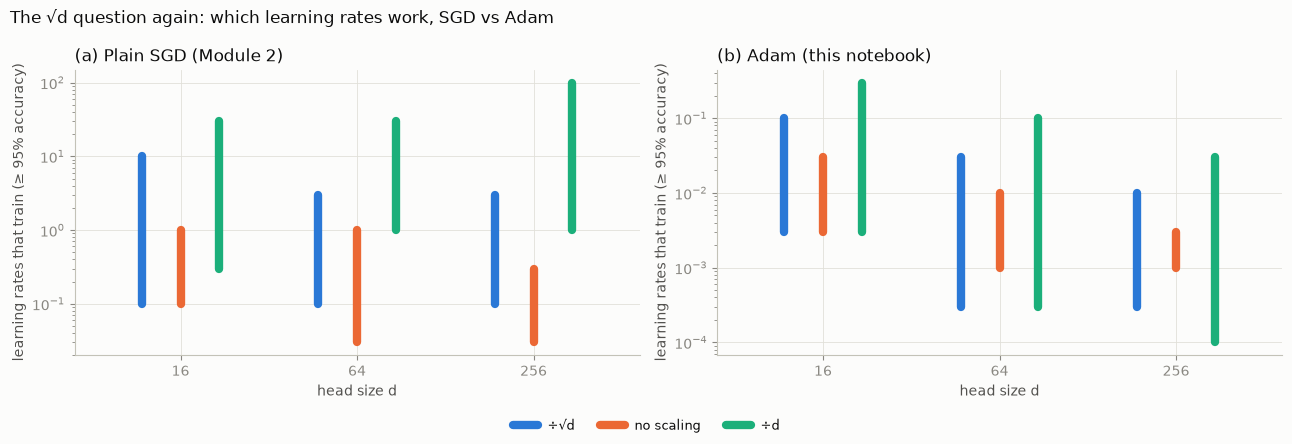

In [15]:
COLORS = {"÷√d": (SERIES[0], "-"), "no scaling": (SERIES[1], "--"), "÷d": (SERIES[2], ":")}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (title, windows) in zip(axes, [("(a) Plain SGD (Module 2)", {k: v for k, v in SGD.items()}),
                                       ("(b) Adam (this notebook)", {name: [adam[d, name] for d in DIMS] for name in SCALES})]):
    for j, name in enumerate(SCALES):
        c, _ = COLORS[name]
        for i, w in enumerate(windows[name]):
            if w is None:
                continue
            x = i + (j - 1) * 0.22
            ax.plot([x, x], list(w), color=c, lw=6, solid_capstyle="round", label=name if i == 0 else None)
    ax.set_yscale("log")
    ax.set_xticks(range(len(DIMS)), [str(d) for d in DIMS])
    ax.set_xlim(-0.6, len(DIMS) - 0.4)
    ax.set_xlabel("head size d")
    ax.set_ylabel("learning rates that train (≥ 95% accuracy)")
    ax.set_title(title, loc="left")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=9)
fig.suptitle("The √d question again: which learning rates work, SGD vs Adam", x=0.01, ha="left", fontsize=12)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

Learning rates that reach ≥ 95%:

| | | d = 16 | d = 64 | d = 256 |
|---|---|---|---|---|
| ÷√d | SGD | 0.1 – 10 | 0.1 – 3 | 0.1 – 3 |
| | **Adam** | 0.003 – 0.1 | 0.0003 – 0.03 | 0.0003 – 0.01 |
| no scaling | SGD | 0.1 – 1 | 0.03 – 1 | 0.03 – 0.3 |
| | **Adam** | 0.003 – 0.03 | 0.001 – 0.01 | 0.001 – 0.003 |
| ÷d | SGD | 0.3 – 30 | 1 – 30 | 1 – 100 |
| | **Adam** | 0.003 – 0.3 | 0.0003 – 0.1 | 0.0001 – 0.03 |

(0.0001 was the smallest learning rate tried, so a window ending there might go further.)

Two results, one of which narrows Module 2's conclusion:

- **√d still helps with Adam**: at every size its window is wider than without scaling (at $d$ = 256, 0.0003 – 0.01 against 0.001 – 0.003), so the "without √d the usable range gets narrower" part holds.
- **But with Adam the whole window moves down as the heads grow.** For ÷√d it goes from 0.003 – 0.1 at $d$ = 16 to 0.0003 – 0.01 at $d$ = 256, about 10× at both ends, and the top falls ~10× for all three scalings. Only 0.003 – 0.01 works at every size, against 0.1 – 3 with SGD, so a learning rate picked from the middle of the $d$ = 16 range (say 0.03) fails at $d$ = 256. The reason is the one from Step 5: Adam moves every weight by about lr whatever its gradient, so the score change per step grows with $d$ however the scores are scaled. Module 2's "tune a small model, make the heads bigger without retuning" still works with Adam, but only inside that narrow band. (Only the edges of each range were measured here, not the best learning rate.) (This is what μP, Yang et al.'s "Tensor Programs V", is about: it shrinks Adam's learning rate with width, and it uses 1/d attention instead of 1/√d. ÷d does have the widest windows here.)

One task, one seed, 300 steps, like Module 2.

## Summary

**Why does training without warmup get stuck?**

1. At init, the gradient at every position says the same thing ("predict the common characters"), so the gradients of the weight matrices point mostly in one direction (80–99% of their energy).
2. Adam turns that into a full-size update (±lr per entry, notebook 2). At lr 3e-2 that one direction is 0.7–4.5× as strong as the strongest direction already in the matrix (6.7× in the token embedding).
3. Block 0 then adds the same large vector to every position. The positions become indistinguishable (position variation ~0.01), so the model can only make the same prediction everywhere: the unigram loss, 3.1.
4. **Causal test:** removing only that direction from each update prevents the collapse; shrinking the update by the same amount does not.
5. **Why warmup works:** it keeps the steps small during exactly the phase where all the gradients agree. Even the "good" learning rate (3e-3) collapses briefly without it.
6. **Not the cause:** attention collapse (the run that trains has larger attention scores) and the biases. Both make the stall *last longer*, so freezing the biases or adding qk-layernorm lets the model escape after ~90–120 steps, but neither prevents it.

Caveats: one model size, one seed, one book, 200-step runs. Sudden loss spikes, the original question, never appeared at this scale. The 8-run table at the top, notebook 2's learning-rate sweep and two side remarks in Step 5 come from scout runs whose code isn't in the repo; everything else is measured in these notebooks.